# 8. Advanced routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/08_routing_advanced.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/08_routing_advanced.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-8.svg" alt="duckOSM notebook manual, chapter 8: Advanced routing" width="100%">

| **You learn** | the graph that all routing calls search; the members of a `Route`; place names; many routes in parallel; the k best routes; a travel time matrix; isochrones; accessibility |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[widget,viz,graph]` (the install cell installs them) |
| **Next** | [9. Street network analysis](09_analysis.md): the numbers of OSMnx, junctions, components and points |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,graph] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## One graph for all routing calls

[7. Routing](07_routing.md) finds one route from A to B. This chapter uses the other calls of the module
`duckosm.routing`. They answer larger questions: the next best routes, a route for each of 100 pairs, the travel time
between all pairs of 100 places, the area that you reach in 10 minutes on foot, and the nearest stop from each street.

All these calls search **the same graph**: the edge graph of the mode (the table `<mode>.edge_graph`). In this graph a
**node is an edge** of the road network, and an **arc is a legal turn** from one edge to the next. A turn that a turn
restriction forbids has no arc. An arc costs the time (`cost_s`) or the length (`length_m`) of its from-edge.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/edge-graph.svg" alt="Four road edges at a junction, and the edge graph: each edge is a node, each legal turn is an arc" width="100%">

The search runs in Rust. Each call opens the database file, reads the graph once, and searches it with Dijkstra's
algorithm.

| Call | Question | Algorithm |
|---|---|---|
| `route(a, b)` | the best route from A to B | bidirectional Dijkstra |
| `routes(origins, destinations)` | the best route for each pair, in parallel | bidirectional Dijkstra, the pairs in parallel |
| `k_shortest_paths(a, b, k)` | the `k` best routes from A to B | Yen's algorithm |
| `matrix(origins, destinations)` | the time from each origin to each destination | one Dijkstra search from each origin |
| `isochrones(origins, minutes)` | the area reached within each time | one Dijkstra search, stopped at the largest time |
| `accessibility(origins, targets, minutes)` | the targets reached from each origin, and the nearest | `matrix` with a time limit |

Each call is a function of the module, `duckosm.routing.matrix(net.driving, ...)`, and also a method of a mode view,
`net.driving.matrix(...)`. This chapter uses the methods.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> All routing calls search the same edge graph, with the same turn rules. So a cell of the matrix is the time of `route` for the same pair, the first of the k best routes is `route`, and an isochrone holds the edges whose matrix time is in the limit.

### Places

Each call takes **places**: the start and the end of a route, the origins and the destinations of a matrix. A place
can be one of three things.

| Place | Example | How it joins the network |
|---|---|---|
| an edge id | `1234567890123` | that edge |
| a `(lon, lat)` point | `(7.4155, 43.7285)` | the nearest edge (`route` with two points: the nearest road within `radius_m`, and the walk to it) |
| a place name | `"Boulevard Albert 1er"` | the middle of the longest edge with that name, else Nominatim in the box of the network |

An edge id is the fastest place: it needs no search for the nearest edge.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The routes use the driving network and the walking network.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                                                                 # the card of the network

Network('monaco.duckdb', 37.0 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

## The Route object

`route` gives a `Route`, or `None` when no route connects the two places. In a notebook a `Route` shows a card with
the number of edges, the length and the time. Here the two places are street names.

In [3]:
r = net.driving.route("Boulevard Albert 1er", "Avenue Princesse Grace")    # from street to street, by car
r                                                                        # the card: edges, length, time

edges,33
length,"1,350 m"
time,2.0 min


The route by car from Boulevard Albert 1er to Avenue Princesse Grace has 33 edges, 1,350 m and 122 s (2.0 minutes). Each name became a point (with `geocode`), so the route starts and ends at the points on the two streets, not at the ends of whole edges.

### What a Route stores, and what it reads from the file

A `Route` is small. It keeps only the result of the search, and two links to the network:

| Stored in the Route | In this example |
|---|---|
| the edge ids, in the order of the route (`r["edges"]`) | 33 edge ids |
| the time and the length (`r["time_s"]`, `r["length_m"]`) | 122 s, 1,350 m |
| the start and the end (`r["start"]`, `r["end"]`): the point, the nearest road point, its `edge_id`, how far along the edge (`fraction`), and the walk to the road (`access_m`, `access_s`) | the end is 12 m from its road |
| the steps of the search (`r["path"]`) | 33 steps |
| the network file, and the mode (hidden: `r._db`, `r._mode`) | `monaco.duckdb`, `driving` |

The `Route` does not store the columns of the edges. When you ask for them, it opens its network file again and
reads the 33 edges with a query (`SELECT ... FROM driving.edges WHERE edge_id IN (...)`), in the order of the route.

| Member | Gives | From |
|---|---|---|
| `r.edge_ids` | the edge ids, in the order of the route | the Route |
| `r.length_m`, `r.time_s` | the sums of `length_m` and `cost_s` of the edges | the Route |
| `r.edges` | a GeoDataFrame of the edges in the order of the route: `seq`, `edge_id` and all the columns of `<mode>.edges` (`name`, `highway` ...) | the file, at each call |
| `r.geometry` | one shapely line (a `MultiLineString` where the edges do not join) | the file, at each call |
| `r.directions()` | the turn-by-turn steps | the file, at each call |
| `r.map()` | the route on the roadstyle map of the network | the file, at each call |

So you can keep thousands of routes in memory, and `r.edges` gives all the columns of the edges table: you can count
the road classes of a route or sum the length of its tunnels.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> `r.edges`, `r.geometry`, `r.directions()` and `r.map()` need the network file. If you move or delete `monaco.duckdb`, they fail. `r["edges"]`, `r.time_s` and `r.length_m` still work.

In [4]:
print(len(r.edge_ids), "edges,", round(r.length_m), "m,", round(r.time_s), "s")    # the sums
r.edges[["seq", "edge_id", "name", "highway", "length_m", "cost_s"]].head()          # the first edges, in order

33 edges, 1350 m, 122 s


,seq,edge_id,name,highway,length_m,cost_s
0,0,2478527519211067132,Boulevard Albert 1er,service,105.471190,18.984814
1,1,570930183709886355,Boulevard Albert 1er,service,25.228455,4.541122
2,2,2037729375342856465,Boulevard Albert 1er,secondary,34.672100,2.496391
3,3,4052179255342490971,Rond-Point Sainte-Dévote,secondary,3.045039,0.219243
4,4,8315515182314187580,Avenue John F. Kennedy,secondary,25.473068,1.834061


In [5]:
r.edges.groupby("highway").length_m.sum().round().sort_values(ascending=False)    # the metres of each road class

highway
secondary    1043.0
tertiary      280.0
service       131.0
Name: length_m, dtype: float64

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The first five edges go along Boulevard Albert 1er, through the roundabout Rond-Point Sainte-Dévote, to Avenue John F. Kennedy. The route has 1,043 m of secondary roads, 280 m of tertiary roads and 131 m of service roads. These sums count whole edges, so they are a little more than the 1,350 m of the card.

### The line and the steps

`r.geometry` joins the lines of the edges into one line. Use it to measure the route, to draw it, or to find the
places near it. `r.directions()` gives the turn-by-turn steps, as [7. Routing](07_routing.md) shows.

In [6]:
print(r.geometry.geom_type, len(r.geometry.coords), "points")    # one line
[step["text"] for step in r.directions()][:5]                   # the first turn-by-turn steps

LineString 83 points


['Head north on Boulevard Albert 1er',
 'At the roundabout, take the 1st exit onto Avenue John F. Kennedy',
 'Continue onto Boulevard Louis II',
 'At the roundabout, take the 2nd exit onto Avenue Princesse Grace',
 'Arrive at your destination']

### The route on the map

`r.map()` draws the route on the map of the network.

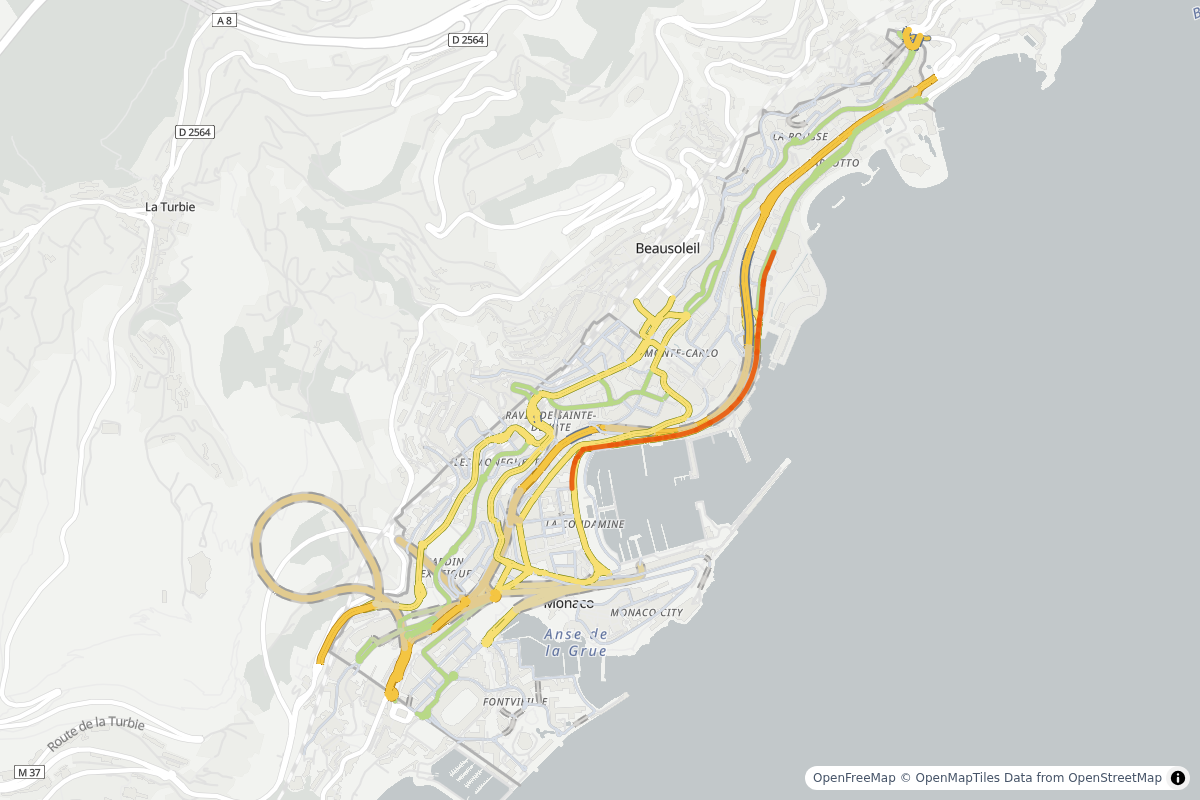

In [7]:
r.map()    # the route on the map

### A Route is also a dict

A `Route` is a Python `dict` too, with the keys of the table above: `edges`, `time_s`, `length_m`, `start`, `end`
and `path`. The code that used the dict of older duckOSM versions works without a change, and `net.map(routes=r)` takes a
`Route`.

In [8]:
sorted(r.keys()), r["edges"][:3]    # the keys of the dict, and the first edge ids

(['edges', 'end', 'length_m', 'path', 'start', 'time_s'],
 [2478527519211067132, 570930183709886355, 2037729375342856465])

## Place names: `geocode`

`duckosm.routing.geocode` gives the `(lon, lat)` of a place name. It looks first in the network: the middle of the
longest edge with that name (the case of the letters does not count). When no edge has the name, it asks Nominatim,
only inside the box of the network. Nominatim needs the internet. `route` calls `geocode` for each name that you
give.

In [9]:
duckosm.routing.geocode(net.driving, "Boulevard Albert 1er")    # a street of the network: no internet

(7.421134960833079, 43.73590722783044)

The point is on Boulevard Albert 1er, the street along the port. The network had
the name, so the call did not use Nominatim.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A name that is not in the network goes to Nominatim. If Nominatim finds nothing in the box of the network, the call stops with the error `no place ... in the network or in Nominatim inside the box of the network`.

## The fastest or the shortest: `weight`

`weight="time"` (the default) gives the fastest route: the sum of `cost_s`. `weight="length"` gives the shortest
route: the sum of `length_m`. All calls of this chapter, except `isochrones` and `accessibility`, take `weight`.

In [10]:
import pandas as pd

ids = net.driving.edges().edge_id.sample(200, random_state=1).tolist()   # 200 driving edges, chosen at random
fast = net.driving.route(ids[0], ids[6])                                  # the fastest route between two of them
short = net.driving.route(ids[0], ids[6], weight="length")                # the shortest route
pd.DataFrame({"fastest": [fast.length_m, fast.time_s], "shortest": [short.length_m, short.time_s]},
             index=["length_m", "time_s"]).round()                              # the two routes side by side

,fastest,shortest
length_m,2049.0,1784.0
time_s,142.0,186.0


Between these two edges the fastest route is 2,049 m and 142 s. The shortest route is 1,784 m, 265 m shorter, but it takes 186 s, 44 s more: it uses slower streets. In a city of steep, narrow streets the two weights often give different routes.

## The k best routes: `k_shortest_paths`

`k_shortest_paths(a, b, k=3)` gives the `k` best routes from A to B, the best first. It uses Yen's algorithm on the
same graph and turn rules as `route`. A route uses each edge one time only. The first route is the route of `route`
for the same two edges. When the graph has fewer than `k` routes, the list is shorter.

Use the next best routes to show a driver two or three choices, or to spread traffic in a simulation over more than
one road.

In [11]:
a, b = r.edge_ids[0], r.edge_ids[-1]                       # the first and the last edge of the route
best = net.driving.k_shortest_paths(a, b, k=3)              # the 3 fastest routes
[(round(x.time_s), round(x.length_m), len(x.edge_ids)) for x in best]    # seconds, metres and edges of each

[(126, 1453, 33), (127, 1459, 35), (127, 1464, 35)]

In [12]:
best[0].edge_ids == net.driving.route(a, b).edge_ids    # the first route is the route of route()

True

The three routes take 126 s, 127 s and 127 s, with 1,453 m, 1,459 m and 1,464 m. The second and the third route have 35 edges, two more than the first. The first route is the same as the route of `route` for the two edges (`True`). The times do not decrease from one route to the next.

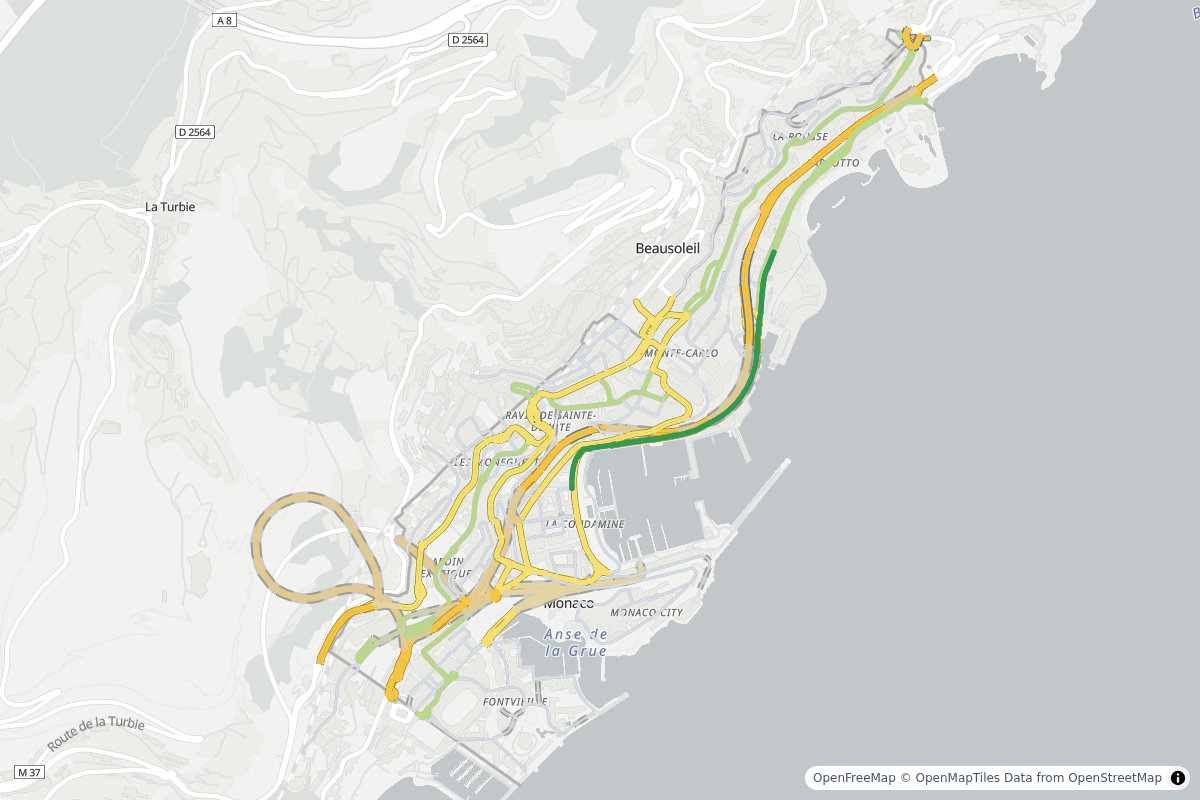

In [13]:
net.map("driving", routes={f"route {i + 1}": x for i, x in enumerate(best)})    # the 3 routes on the map

## Many routes in parallel: `routes`

`routes(origins, destinations)` takes two lists of the same length. It finds the route from each origin to the
destination at the same place in the other list, as Python's `zip` pairs them. The pairs run in parallel on all
the cores of the computer. The result is a list of `Route`, with `None` for a pair that no route connects.

Here the places are the 200 random driving edges of the section above: 100 origins and 100 destinations.

In [14]:
import time

t = time.perf_counter()                                       # start the clock
many = net.driving.routes(ids[:100], ids[100:])               # 100 routes
print(f"100 routes in {time.perf_counter() - t:.2f} s")       # the time
sum(x is not None for x in many)                              # the routes found

100 routes in 0.12 s


90

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The 100 routes took about 0.1 s. 90 pairs have a route. The other 10 pairs have `None`: one of their edges cannot reach the other, for example an edge in a garage that only leaves the network, or an edge that is not in the graph of the mode (see `routed_graph` below). The histogram shows that most routes take 1.5 to 4.5 minutes by car, and the longest take about 7 minutes.

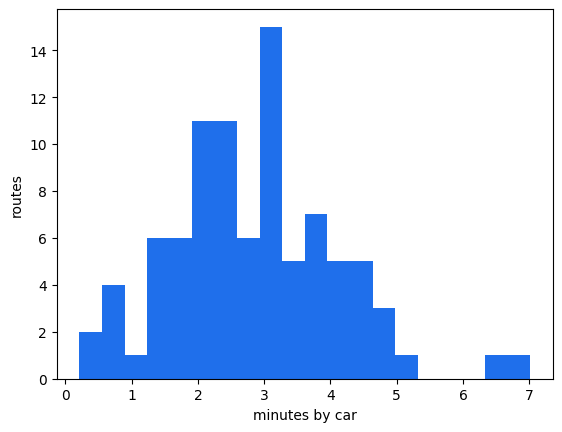

In [15]:
import matplotlib.pyplot as plt

times = [x.time_s / 60 for x in many if x is not None]        # the time of each route in minutes
plt.hist(times, bins=20, color="#1f6feb")                     # a histogram
plt.xlabel("minutes by car"); plt.ylabel("routes"); plt.show()    # the labels

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> The two lists must have the same length. `routes([e1, e2], [e3])` stops with the error `2 origins and 1 destinations: give the same number`. For all pairs of two lists, use `matrix`.

## A travel time matrix: `matrix`

`matrix(origins, destinations)` gives the travel time from each origin to each destination, as a pandas DataFrame:
one row for each origin, one column for each destination. A cell is in seconds (`weight="length"`: in metres). Without
`destinations`, the destinations are the origins.

The matrix does not find one route for each cell. It runs one Dijkstra search from each origin, and this search
reaches all destinations. The origins run in parallel. So a matrix of 100 × 100 places costs about as much as 100
routes.

| Argument | Default | What it does |
|---|---|---|
| `origins` | | the places of the rows |
| `destinations` | `None` | the places of the columns (`None`: the origins) |
| `weight` | `"time"` | `"length"`: metres, not seconds |
| `max_cost` | `None` | the largest cell: each search stops there, and a larger cell is `NaN` |

A cell is `NaN` when no route connects the pair, when the cost is more than `max_cost`, or when the edge is not in the
graph of the mode (for example an edge for buses only).

In [16]:
t = time.perf_counter()                                       # start the clock
m = net.driving.matrix(ids[:100])                             # 100 x 100 travel times in seconds
print(f"100 x 100 matrix in {time.perf_counter() - t:.2f} s") # the time
m.iloc[:5, :5].round()                                        # the first cells

100 x 100 matrix in 0.10 s


,3050652600567400442,4119412884669195015,8277540089478770184,1389707648760686556,7815454498997486282
3050652600567400442,6.0,96.0,126.0,169.0,60.0
4119412884669195015,121.0,0.0,151.0,228.0,85.0
8277540089478770184,165.0,165.0,13.0,266.0,127.0
1389707648760686556,203.0,232.0,263.0,3.0,196.0
7815454498997486282,111.0,112.0,104.0,213.0,1.0


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The 100 × 100 matrix took about 0.1 s too: the time of the 100 routes, for 100 times more cells. The rows and the columns have the edge ids as their labels. A cell on the diagonal is the time of the edge itself: from its start to its end (6 s for the first edge). The matrix is not symmetric: 96 s from the first edge to the second, but 121 s back, because of the one-way streets.

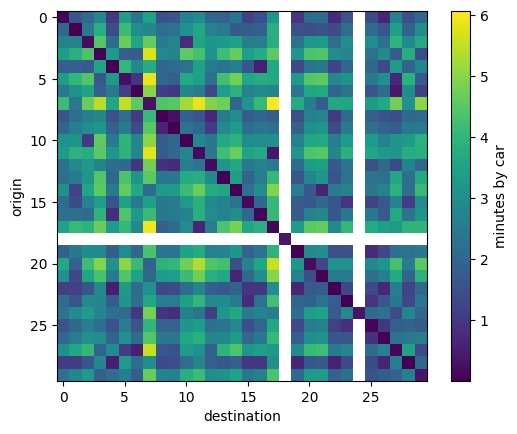

In [17]:
plt.imshow(m.iloc[:30, :30] / 60, cmap="viridis")           # a heat map of 30 x 30 cells, in minutes
plt.colorbar(label="minutes by car")                          # the scale
plt.xlabel("destination"); plt.ylabel("origin"); plt.show()   # the labels

### A cell equals the route

A cell is the time of `route` for the same two edges: from the start of the origin edge to the end of the destination
edge. The tests of duckOSM check this rule for each cell.

In [18]:
round(m.iloc[0, 1]) == round(net.driving.route(ids[0], ids[1]).time_s)    # a cell equals the route

True

### A time limit: `max_cost`

`max_cost` stops each search at that cost. A cell above it is `NaN`. Use it for a large matrix when only the near
places count: the search then reads a small part of the graph.

In [19]:
near = net.driving.matrix(ids[:100], max_cost=120)    # only the cells of 2 minutes or less
print(f"{near.notna().to_numpy().mean():.0%} of the cells are 2 minutes or less")    # the share of cells with a value

27% of the cells are 2 minutes or less


With `max_cost=120`, 27 % of the cells have a value. The other cells are `NaN`, because they cost more than 2 minutes or no route connects them.

### Points and names as places

The origins and the destinations can be points and names too. The rows and the columns then have the numbers
`0, 1, 2 ...`. When all places are edge ids or names, the rows and the columns have the places as their labels.

In [20]:
places = ["Boulevard Albert 1er", "Avenue Princesse Grace", "Boulevard de Suisse"]    # three streets
(net.driving.matrix(places, weight="length") / 1000).round(2)                          # the distances in km

,Boulevard Albert 1er,Avenue Princesse Grace,Boulevard de Suisse
Boulevard Albert 1er,0.11,1.88,1.46
Avenue Princesse Grace,2.08,0.12,1.76
Boulevard de Suisse,1.66,2.15,0.09


The rows and the columns have the three names. With `weight="length"` the cells are metres, and the code divides them by 1,000. From Boulevard Albert 1er to Avenue Princesse Grace is 1.88 km, and the way back is 2.08 km. The diagonal is the length of the edge of the name (0.09 to 0.12 km).

## Isochrones: `isochrones`

An **isochrone** is the area that you reach from a place within a time. `isochrones(origins, minutes)` gives one
polygon for each origin and each time, as a GeoDataFrame with the columns `origin`, `minutes`, `n_edges` and
`geometry`.

An edge is in the isochrone of `m` minutes when you reach the end of the whole edge within `m` minutes. Each reached
edge gets a buffer of `buffer_m` metres (default 25 m), and the polygon is the union of the buffers. The polygon is
not a hull around the edges: a park or a block with no road stays out of it.

| Argument | Default | What it does |
|---|---|---|
| `origins` | | the start places, one polygon set for each |
| `minutes` | `(5, 10, 15)` | the times: a number or a list |
| `buffer_m` | `25.0` | the width of the buffer around each reached edge, in metres |

Here the origin is the casino square, on foot.

In [21]:
casino = (7.4280, 43.7393)                                           # Place du Casino (lon, lat)
iso = net.walking.isochrones([casino], minutes=[5, 10, 15])          # three walking times
iso[["minutes", "n_edges"]].assign(km2=iso.to_crs(iso.estimate_utm_crs()).area / 1e6).round(3)    # edges and area

,minutes,n_edges,km2
0,5.0,1525,0.238
1,10.0,3483,0.645
2,15.0,5983,1.148


From the casino square, 1,525 walking edges are within 5 minutes, 3,483 within 10 minutes and 5,983 within 15 minutes. The areas are 0.24 km², 0.65 km² and 1.15 km². In the picture each polygon follows the streets and the steps, not a circle: the hills and the sea limit the walk.

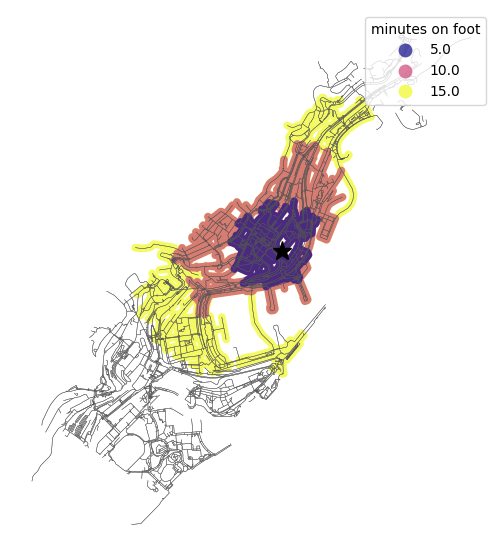

In [22]:
fig, ax = plt.subplots(figsize=(7, 7))                                           # one picture
iso.iloc[::-1].plot(ax=ax, column="minutes", categorical=True, cmap="plasma", alpha=0.7, legend=True,
                    legend_kwds={"title": "minutes on foot"})                    # the polygons, the largest below
net.walking.edges().plot(ax=ax, color="#555555", linewidth=0.3)                  # the walking roads, thin and gray
ax.plot(*casino, "k*", markersize=14); ax.set_axis_off(); plt.show()             # the start

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The walking speed comes from `cost_s` of the walking edges. For more than one origin, give a list: each origin gets its own polygons, with its place in the column `origin`.

## Accessibility: `accessibility`

`accessibility(origins, targets, minutes)` answers: how many targets can I reach from each origin, and which target is
the nearest? The targets can be bus stops, schools, shops or sensors. The result is a DataFrame with one row for each
origin and these columns:

| Column | What it is |
|---|---|
| `n_<m>min` | the number of targets within `m` minutes, one column for each time |
| `nearest` | the nearest target (its label, or its number in the list) |
| `nearest_s` | the time to the nearest target, in seconds |

The call uses `matrix` with `max_cost` at the largest time, so a target farther than that has no time, and an origin
with no target in the time has `None` and `NaN`. Here each walking edge is an origin, and the targets are three
points.

In [23]:
stops = [(7.4155, 43.7285), (7.4246, 43.7384), (7.4335, 43.7468)]    # three targets: Fontvieille, the port, Larvotto
homes = net.walking.edges().edge_id.tolist()                         # each walking edge is an origin
t = time.perf_counter()                                              # start the clock
acc = net.walking.accessibility(homes, stops, minutes=[5, 10])       # the targets within 5 and 10 minutes
print(f"{len(homes):,} origins in {time.perf_counter() - t:.2f} s")  # the time
acc.head()                                                           # a row for each origin edge

11,938 origins in 0.59 s


,n_5min,n_10min,nearest,nearest_s
414242052250797,0,1,2,536.303398
901203926603589,1,1,0,279.352130
2214154189574909,0,1,0,316.343565
2362608876371269,0,0,None,NaN
2686560736896665,0,2,2,484.165528


In [24]:
acc[["n_5min", "n_10min"]].apply(lambda c: c.value_counts().sort_index()).fillna(0).astype(int)    # origins for each count of targets

,n_5min,n_10min
0,8721,3416
1,3217,8194
2,0,328


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The call found the targets of all 11,938 walking edges in about half a second. With 5 minutes, 3,217 edges reach one stop, and 8,721 edges reach none. With 10 minutes, 8,194 edges reach one stop, 328 edges reach two, and 3,416 edges reach none. An edge with no stop in 10 minutes has `None` in `nearest` and `NaN` in `nearest_s`, and it stays gray on the map. The dark edges around the three stops are the nearest. The yellow edges are about 9 minutes away.

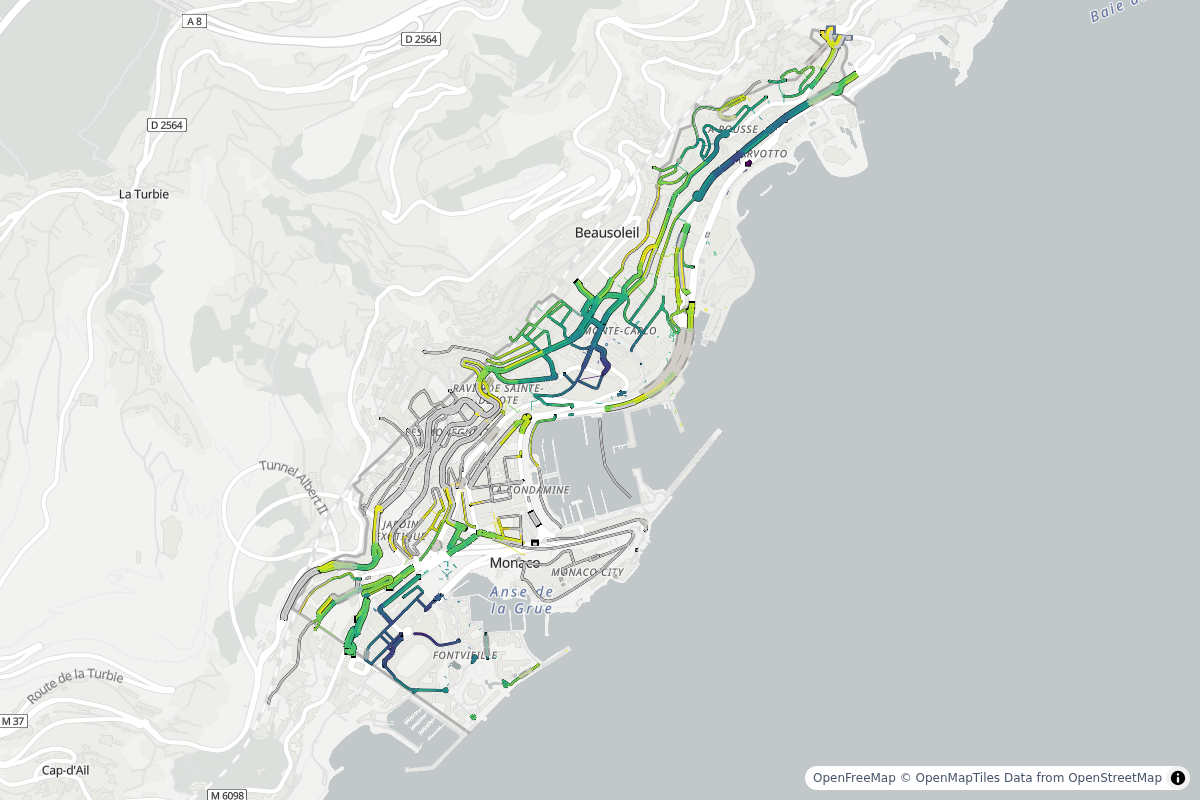

In [25]:
net.map("walking", color_by=acc["nearest_s"] / 60, cmap="viridis")    # each edge colored by the minutes to its nearest target

## The graph of all calls: `routed_graph`

`duckosm.routing.routed_graph` gives the SQL relation of the arcs that a mode routes on: the rows of
`<mode>.edge_graph` for that mode. Use it in your own SQL, for example to count the arcs or to find the edges where a
route can start.

In [26]:
g = duckosm.routing.routed_graph(net.driving)                     # an SQL relation, as text
print(g)
net.sql(f"SELECT count(*) AS arcs, count(DISTINCT from_edge) AS edges FROM {g}")    # the size of the graph

(SELECT * FROM driving.edge_graph WHERE uses = 'car')


,arcs,edges
0,5082,2814


The driving graph is the rows of `driving.edge_graph` with `uses = 'car'`. It has 5,082 arcs (legal turns) that start on 2,814 edges. The network has 2,840 driving edges, so 26 edges have no turn out: a route can end on them, but it cannot start there.

## Try it yourself

**1.** Find the three best walking routes from the casino square to the port, and compare their times.

<details><summary>Show the answer</summary>

```python
walk = net.walking.k_shortest_paths((7.4280, 43.7393), (7.4246, 43.7384), k=3)
[round(x.time_s / 60, 1) for x in walk]      # minutes of each route
```
</details>

**2.** Make a matrix of walking distances in metres between the three stops of the accessibility section.

<details><summary>Show the answer</summary>

```python
net.walking.matrix(stops, weight="length").round()     # rows and columns 0, 1, 2
```
</details>

**3.** Draw the 5 and 10 minute isochrones by car from the port, with a buffer of 40 m.

<details><summary>Show the answer</summary>

```python
iso_car = net.driving.isochrones([(7.4246, 43.7384)], minutes=[5, 10], buffer_m=40)
iso_car.iloc[::-1].plot(column="minutes", categorical=True, legend=True)
```
</details>

**4.** Find the walking edges that have no stop within 10 minutes.

<details><summary>Show the answer</summary>

```python
far = acc[acc.n_10min == 0].index           # the origin edge ids
net.map("walking", highlight=list(far))
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| edge graph | the graph that routing searches: a node is an edge of the network, an arc is a legal turn |
| arc | one legal turn from one edge to the next. It costs the time or the length of its from-edge |
| place | the start or the end of a route: an edge id, a `(lon, lat)` point or a place name |
| `Route` | the result of a route: the edges, the length, the time, the line, the steps and a map |
| weight | what a route makes smallest: `"time"` (`cost_s`) or `"length"` (`length_m`) |
| Dijkstra's algorithm | a search that finds the cheapest route from one place to all other places |
| Yen's algorithm | a search that finds the `k` best routes that use no edge two times |
| matrix | a table of the travel times (or distances) from each origin to each destination |
| isochrone | the area that you reach from a place within a time |
| accessibility | the number of targets that you reach from a place within a time, and the nearest one |

## Summary

| Call | Does |
|---|---|
| `net.driving.route(a, b, weight=...)` | the best route, a `Route` (or `None`) |
| `r.edge_ids`, `r.edges`, `r.length_m`, `r.time_s` | the edges and the sums of a route |
| `r.geometry`, `r.directions()`, `r.map()` | the line, the steps and the map of a route |
| `duckosm.routing.geocode(view, name)` | the `(lon, lat)` of a place name |
| `net.driving.k_shortest_paths(a, b, k=3)` | the `k` best routes, the best first |
| `net.driving.routes(origins, destinations)` | a route for each pair (`zip`), in parallel |
| `net.driving.matrix(origins, destinations, max_cost=...)` | a travel time (or distance) matrix, a DataFrame |
| `net.walking.isochrones(origins, minutes, buffer_m=...)` | the polygons reached within each time |
| `net.walking.accessibility(origins, targets, minutes)` | the targets reached from each origin, and the nearest |
| `duckosm.routing.routed_graph(view)` | the SQL relation of the graph of all calls |

The reference: [duckosm.routing](../reference/sdk/routing.md). **Next:** [9. Street network analysis](09_analysis.md), the numbers of OSMnx, junctions, components and points.